# Backbone mô hình: từ 16 ảnh đến một cảnh báo

Notebook này là **bản chạy thật của slide 11**. Toàn bộ kiến trúc được viết ngay trong file, không gọi `VideoMAEModel` hay `nn.TransformerEncoder` để giấu đi phần nào:

| Slide 11 | Ở đâu trong notebook | Class / hàm |
|---|---|---|
| ① 16 ảnh 224×224, 7.5 ảnh/giây | Bước 1 | `read_sampled`, `preprocess` |
| ② 1568 khối 2×16×16 + mã vị trí | Bước 2 | `TubeletEmbedding`, `sincos_position_table` |
| ③ **12 lớp Transformer**, 12 đầu chú ý | Bước 3 | `VideoMAEAttention`, `VideoMAEBlock`, `VideoMAE.blocks` |
| ④ Trung bình 1568 → 1, vector 768 chiều | Bước 4 | `VideoMAE.forward`, `extract_features` |
| ⑤ Ghép 18 vector | Bước 5 | `make_sequences` |
| ⑥ Linear + LayerNorm + mã sin/cos | Bước 6 | `FeatureTransformer.embed`, `PositionalEncoding` |
| ⑦ **Encoder × 2 lớp**, self-attention 8 đầu, FFN | Bước 7 | `TemporalSelfAttention`, `TemporalEncoderLayer` |
| ⑧ Trung bình 18 → 1, Linear 768 → 10, gộp 3 góc | Bước 8 | `FeatureTransformer.forward`, `predict_probs` |
| ⑨ Quy tắc chuyển trạng thái | Bước 9 | `rule_condition`, `StreamRule` |
| ⑩ Báo động | Bước 10 | `StreamRule._update_alarm` |

Trọng số là **trọng số thật**: VideoMAE của Kinetics-400 và Transformer thời gian đã fine-tune. Bước 3 và Bước 7 có phép so sánh để chứng minh code viết tay cho kết quả giống mô hình gốc.

**Cần để chạy:** `torch`, `transformers`, `opencv-python`, `matplotlib`, `pandas`; checkpoint `outputs_v2/finetune/baseline_ft_itw_seed42.pt`; một video (đặt biến môi trường `FALL_VIDEO`, hoặc có dữ liệu OOPS trong `data/`). Mở notebook từ thư mục `notebooks/`.

## Cài đặt và mọi thông số của slide 11

In [1]:
from __future__ import annotations

import math
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("USE_TF", "0")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Đầu vào
IMG_SIZE, TARGET_FPS, WINDOW_FRAMES = 224, 7.5, 16
CROPS = ("center", "start", "end")       # giữa / trái / phải (video ngang)

# Tầng 1: VideoMAE-Base
TUBELET, PATCH, VMAE_DIM = 2, 16, 768
VMAE_LAYERS, VMAE_HEADS, VMAE_FFN = 12, 12, 3072
VIDEOMAE_NAME = "MCG-NJU/videomae-base-finetuned-kinetics"

# Tầng 2: Transformer thời gian
NUM_FEATURES, HIDDEN_DIM = 18, 768
ENC_LAYERS, ENC_HEADS, ENC_FFN, ENC_DROPOUT = 2, 8, 3072, 0.1
CLASS_NAMES = ["walk", "fall", "fallen", "sit_down", "sitting",
               "lie_down", "lying", "stand_up", "standing", "other"]
NUM_CLASSES = len(CLASS_NAMES)
FT_CKPT = ROOT / "outputs_v2" / "finetune" / "baseline_ft_itw_seed42.pt"

# Tầng 3: quy tắc và báo động (cấu hình `stream_ft` chọn trên tập val)
FALL, FALLEN = 1, 2
TRANSIENT_TO_STATIC = {1: 2, 3: 4, 5: 6, 7: 8}   # đang ngã -> đã ngã, ngồi xuống -> đang ngồi, ...
TAU, RULE_WINDOW, SEGMENT_HOP = 1.0, 5.0, 0.5
ALARM_ON, ALARM_OFF = 1.0, 3.0

STRIDE = 1 / TARGET_FPS
print("Thiết bị:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print(f"Mỗi cụm: {WINDOW_FRAMES} ảnh = {WINDOW_FRAMES / TARGET_FPS:.2f} s | bước trượt {STRIDE:.3f} s")
print(f"18 vector phủ {(NUM_FEATURES - 1) * STRIDE + WINDOW_FRAMES / TARGET_FPS:.2f} s")

Thiết bị: cuda | NVIDIA GeForce RTX 3070
Mỗi cụm: 16 ảnh = 2.13 s | bước trượt 0.133 s
18 vector phủ 4.40 s


## Bước 1. Lấy 16 ảnh 224×224 ở 7.5 ảnh/giây

Ảnh được chọn theo **thời gian thật**: mốc tiếp theo cách mốc trước 1/7.5 giây, nên video 24 hay 30 fps đều cho đúng nhịp. Đây là cách sửa lỗi lệch thời gian.

Video minh họa thuộc tập test và được **chọn vì mô hình báo động đúng**, để thấy đủ cả 10 bước. Đây không phải kết quả tổng thể: trên toàn tập test, hệ thống chỉ bắt được khoảng 34.5% số lần ngã (xem notebook 07).

Mỗi ảnh được thu nhỏ cho cạnh ngắn bằng 224, chuẩn hóa theo mean/std ImageNet, rồi cắt thành **3 ô vuông trái/giữa/phải** để không mất 44% khung hình.

In [2]:
DEMO_VIDEO = "falls/Ready_Set_FailFailsoftheWeekSeptember2018_FailArmy25"


def find_video() -> Path:
    if os.environ.get("FALL_VIDEO"):
        return Path(os.environ["FALL_VIDEO"])
    f = ROOT / "data" / "omnifall" / "OOPS" / "video" / f"{DEMO_VIDEO}.mp4"
    if f.exists():
        return f
    raise FileNotFoundError("Chưa có video: đặt biến môi trường FALL_VIDEO=<đường dẫn video>")


def read_sampled(path: Path, max_seconds: float = 25.0):
    # Trả về danh sách ảnh RGB và thời điểm thật của từng ảnh, lấy mẫu 7.5 ảnh/giây
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    frames, times, next_t, i = [], [], 0.0, 0
    while True:
        ok, bgr = cap.read()
        t = i / fps
        if not ok or t > max_seconds:
            break
        if t + 1e-6 >= next_t:
            while next_t <= t:
                next_t += 1.0 / TARGET_FPS
            frames.append(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
            times.append(t)
        i += 1
    cap.release()
    return frames, np.array(times), fps


MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def preprocess(frames_rgb: list, crops=CROPS, size: int = IMG_SIZE) -> torch.Tensor:
    # (N, H, W, 3) uint8 -> (số góc, N, 3, 224, 224) đã chuẩn hóa
    x = torch.from_numpy(np.stack(frames_rgb)).to(DEVICE).permute(0, 3, 1, 2).float()
    h, w = x.shape[-2:]
    nh, nw = (size, int(size * w / h)) if h <= w else (int(size * h / w), size)
    x = F.interpolate(x, size=(nh, nw), mode="bilinear", align_corners=False, antialias=True)
    x = (x / 255.0 - MEAN.to(DEVICE)) / STD.to(DEVICE)
    out = []
    for c in crops:
        top = {"center": (nh - size) // 2, "start": 0, "end": nh - size}[c]
        left = {"center": (nw - size) // 2, "start": 0, "end": nw - size}[c]
        out.append(x[..., top:top + size, left:left + size])
    return torch.stack(out)


VIDEO = find_video()
frames, times, src_fps = read_sampled(VIDEO)
pixels = preprocess(frames)
H, W = frames[0].shape[:2]
print(f"Video: {VIDEO.name} | {W}x{H} | {src_fps:.2f} fps | dài {times[-1]:.1f} s")
print(f"Lấy được {len(frames)} ảnh, nhịp thực tế {1 / np.diff(times).mean():.2f} ảnh/giây")
print("pixels:", tuple(pixels.shape), "= (số góc, số ảnh, kênh màu, cao, rộng)")
print(f"Một ô vuông chỉ giữ {100 * min(W, H) / max(W, H):.0f}% chiều dài khung hình")

Video: Ready_Set_FailFailsoftheWeekSeptember2018_FailArmy25.mp4 | 1280x720 | 29.97 fps | dài 12.0 s
Lấy được 91 ảnh, nhịp thực tế 7.49 ảnh/giây
pixels: (3, 91, 3, 224, 224) = (số góc, số ảnh, kênh màu, cao, rộng)
Một ô vuông chỉ giữ 56% chiều dài khung hình


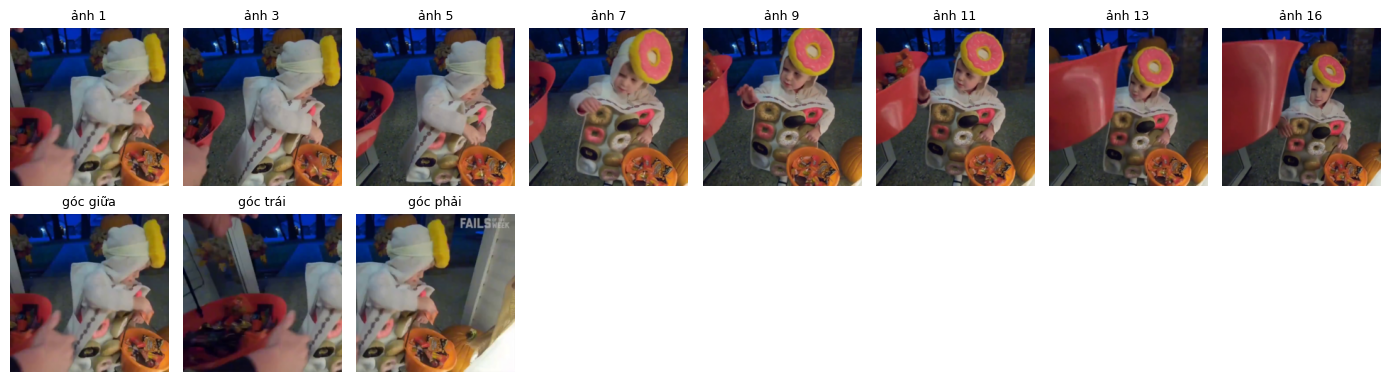

In [3]:
def show(t):
    return (t * STD.to(t.device) + MEAN.to(t.device)).clamp(0, 1).permute(1, 2, 0).cpu().numpy()


fig, ax = plt.subplots(2, 8, figsize=(14, 4))
idx = np.linspace(0, WINDOW_FRAMES - 1, 8).astype(int)
for j, i in enumerate(idx):
    ax[0, j].imshow(show(pixels[0, i])); ax[0, j].set_title(f"ảnh {i + 1}", fontsize=9)
for j, name in enumerate(["giữa", "trái", "phải"]):
    ax[1, j].imshow(show(pixels[j, 0])); ax[1, j].set_title(f"góc {name}", fontsize=9)
for a in ax.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

## Bước 2. Cắt thành 1568 khối và thêm mã vị trí

`Conv3d` với kernel `(2, 16, 16)` và bước nhảy bằng kernel chính là phép cắt khối: mỗi khối gồm 2 ảnh liền nhau và ô 16×16 px, được biến thành 768 số.

Số khối là `(16/2) × (224/16) × (224/16) = 8 × 14 × 14 = 1568`.

Mã vị trí là bảng sin/cos **cố định**, không học. Nó được tính theo số thứ tự của khối sau khi trải phẳng.

In [4]:
class TubeletEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Conv3d(3, VMAE_DIM, kernel_size=(TUBELET, PATCH, PATCH),
                                    stride=(TUBELET, PATCH, PATCH))

    def forward(self, x):
        # x: (B, 16, 3, 224, 224) -> Conv3d cần (B, 3, 16, 224, 224)
        x = self.projection(x.permute(0, 2, 1, 3, 4))   # (B, 768, 8, 14, 14)
        return x.flatten(2).transpose(1, 2)             # (B, 1568, 768)


def sincos_position_table(n: int, dim: int) -> torch.Tensor:
    pos = np.arange(n)[:, None]
    div = np.power(10000.0, 2 * (np.arange(dim) // 2) / dim)
    table = pos / div
    table[:, 0::2] = np.sin(table[:, 0::2])
    table[:, 1::2] = np.cos(table[:, 1::2])
    return torch.tensor(table, dtype=torch.float32)[None]


NUM_PATCHES = (WINDOW_FRAMES // TUBELET) * (IMG_SIZE // PATCH) ** 2
print("Số khối:", NUM_PATCHES)
print("Bảng mã vị trí:", tuple(sincos_position_table(NUM_PATCHES, VMAE_DIM).shape))

Số khối: 1568
Bảng mã vị trí: (1, 1568, 768)


## Bước 3. 12 lớp Transformer của VideoMAE

**Đây là chỗ có 12 lớp:** `self.blocks` trong class `VideoMAE`, gồm 12 `VideoMAEBlock` giống hệt nhau về cấu trúc.

Mỗi block có 2 phần, phần nào cũng có LayerNorm đứng trước và nối tắt:
1. **Self-attention 12 đầu:** mỗi khối nhìn toàn bộ 1568 khối, gồm cả các khối cùng ảnh và khác ảnh.
2. **FFN 768 → 3072 → 768:** từng khối tự xử lý những gì vừa thu thập.

Với 12 đầu, vector 768 chiều được chia thành 12 phần 64 chiều.

In [5]:
class VideoMAEAttention(nn.Module):
    def __init__(self, dim=VMAE_DIM, heads=VMAE_HEADS):
        super().__init__()
        self.heads, self.head_dim = heads, dim // heads
        self.query = nn.Linear(dim, dim, bias=False)
        self.key = nn.Linear(dim, dim, bias=False)
        self.value = nn.Linear(dim, dim, bias=False)
        self.q_bias = nn.Parameter(torch.zeros(dim))
        self.v_bias = nn.Parameter(torch.zeros(dim))
        self.out = nn.Linear(dim, dim)

    def split(self, x):
        B, N, _ = x.shape
        return x.view(B, N, self.heads, self.head_dim).transpose(1, 2)   # (B, đầu, N, 64)

    def forward(self, x):
        q = self.split(F.linear(x, self.query.weight, self.q_bias))
        k = self.split(F.linear(x, self.key.weight))
        v = self.split(F.linear(x, self.value.weight, self.v_bias))
        weights = (q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)).softmax(-1)
        z = (weights @ v).transpose(1, 2).flatten(2)                     # ghép 12 đầu lại thành 768 chiều
        return self.out(z)


class VideoMAEBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm_before = nn.LayerNorm(VMAE_DIM, eps=1e-12)
        self.attention = VideoMAEAttention()
        self.norm_after = nn.LayerNorm(VMAE_DIM, eps=1e-12)
        self.ffn_up = nn.Linear(VMAE_DIM, VMAE_FFN)
        self.ffn_down = nn.Linear(VMAE_FFN, VMAE_DIM)

    def forward(self, x):
        x = x + self.attention(self.norm_before(x))
        return x + self.ffn_down(F.gelu(self.ffn_up(self.norm_after(x))))


class VideoMAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.tubelet = TubeletEmbedding()
        self.register_buffer("position", sincos_position_table(NUM_PATCHES, VMAE_DIM), persistent=False)
        self.blocks = nn.ModuleList(VideoMAEBlock() for _ in range(VMAE_LAYERS))    # 12 LỚP Ở ĐÂY

    def encode(self, pixels):
        x = self.tubelet(pixels) + self.position
        for block in self.blocks:
            x = block(x)
        return x                                  # (B, 1568, 768)

    def forward(self, pixels):
        return self.encode(pixels).mean(1)        # Bước 4: trung bình 1568 -> 1, ra (B, 768)

### Nạp trọng số thật và kiểm chứng

Trọng số được tải từ HuggingFace rồi chép vào đúng từng lớp ở trên. `load_state_dict(strict=True)` sẽ báo lỗi nếu thiếu hay thừa bất kỳ tham số nào. Sau đó cho code viết tay và `VideoMAEModel` gốc xử lý **cùng một cụm ảnh thật**, rồi đo độ chênh lệch.

In [6]:
from transformers import VideoMAEModel


def videomae_state_from_hf(sd: dict) -> dict:
    out = {"tubelet.projection.weight": sd["embeddings.patch_embeddings.projection.weight"],
           "tubelet.projection.bias": sd["embeddings.patch_embeddings.projection.bias"]}
    for i in range(VMAE_LAYERS):
        a, b = f"encoder.layer.{i}.", f"blocks.{i}."
        for mine, theirs in {
            "attention.query.weight": "attention.attention.query.weight",
            "attention.key.weight": "attention.attention.key.weight",
            "attention.value.weight": "attention.attention.value.weight",
            "attention.q_bias": "attention.attention.q_bias",
            "attention.v_bias": "attention.attention.v_bias",
            "attention.out.weight": "attention.output.dense.weight",
            "attention.out.bias": "attention.output.dense.bias",
            "ffn_up.weight": "intermediate.dense.weight", "ffn_up.bias": "intermediate.dense.bias",
            "ffn_down.weight": "output.dense.weight", "ffn_down.bias": "output.dense.bias",
            "norm_before.weight": "layernorm_before.weight", "norm_before.bias": "layernorm_before.bias",
            "norm_after.weight": "layernorm_after.weight", "norm_after.bias": "layernorm_after.bias",
        }.items():
            out[b + mine] = sd[a + theirs]
    return out


hf = VideoMAEModel.from_pretrained(VIDEOMAE_NAME).to(DEVICE).eval()
videomae = VideoMAE().to(DEVICE).eval()
print(videomae.load_state_dict(videomae_state_from_hf(hf.state_dict()), strict=True))
for p in videomae.parameters():
    p.requires_grad_(False)                   # đóng băng: tầng 1 không học thêm

with torch.no_grad():
    clip = pixels[:1, :WINDOW_FRAMES]         # góc giữa, 16 ảnh đầu tiên
    mine = videomae(clip)
    gold = hf(pixel_values=clip).last_hidden_state.mean(1)
print("Số lớp trong self.blocks:", len(videomae.blocks))
print("Vector ra:", tuple(mine.shape))
print(f"Chênh lệch lớn nhất so với VideoMAE gốc: {(mine - gold).abs().max().item():.2e}")
assert (mine - gold).abs().max() < 1e-3
del hf
torch.cuda.empty_cache() if DEVICE == "cuda" else None

<All keys matched successfully>
Số lớp trong self.blocks: 12
Vector ra: (1, 768)


Chênh lệch lớn nhất so với VideoMAE gốc: 6.91e-06


### Theo dõi dữ liệu đi qua từng lớp

Kích thước giữ nguyên `[1568 × 768]` qua cả 12 lớp, chỉ **ý nghĩa** của các con số thay đổi. Cột *thay đổi so với lớp trước* đo xem mỗi lớp biến đổi dữ liệu bao nhiêu (1 − cosine trung bình).

In [7]:
def count(m):
    return sum(p.numel() for p in m.parameters())


rows = []
with torch.no_grad():
    x = videomae.tubelet(clip)
    rows.append({"giai đoạn": "khối + (chưa có mã vị trí)", "kích thước": str(tuple(x.shape[1:])), "tham số": count(videomae.tubelet), "thay đổi so với lớp trước": None})
    x = x + videomae.position
    for i, block in enumerate(videomae.blocks, 1):
        y = block(x)
        change = 1 - F.cosine_similarity(x, y, dim=-1).mean().item()
        rows.append({"giai đoạn": f"lớp {i}/12", "kích thước": str(tuple(y.shape[1:])), "tham số": count(block), "thay đổi so với lớp trước": round(change, 3)})
        x = y
trace = pd.DataFrame(rows)
print(trace.to_string(index=False))

b = videomae.blocks[0]
detail = {"attention (Q, K, V, out)": count(b.attention), "FFN 768→3072→768": count(b.ffn_up) + count(b.ffn_down),
          "2 LayerNorm": count(b.norm_before) + count(b.norm_after), "cả một lớp": count(b)}
print("\nTham số trong một lớp:", {k: f"{v:,}" for k, v in detail.items()})
print(f"Tổng tầng 1: {count(videomae):,}  (slide: 86M)")
assert count(videomae) == 86_225_664

                 giai đoạn  kích thước  tham số  thay đổi so với lớp trước
khối + (chưa có mã vị trí) (1568, 768)  1180416                        NaN
                  lớp 1/12 (1568, 768)  7087104                      0.472
                  lớp 2/12 (1568, 768)  7087104                      0.107
                  lớp 3/12 (1568, 768)  7087104                      0.073
                  lớp 4/12 (1568, 768)  7087104                      0.060
                  lớp 5/12 (1568, 768)  7087104                      0.051
                  lớp 6/12 (1568, 768)  7087104                      0.054
                  lớp 7/12 (1568, 768)  7087104                      0.049
                  lớp 8/12 (1568, 768)  7087104                      0.056
                  lớp 9/12 (1568, 768)  7087104                      0.065
                 lớp 10/12 (1568, 768)  7087104                      0.077
                 lớp 11/12 (1568, 768)  7087104                      0.174
                 lớp 12/1

## Bước 4. Từ video thành chuỗi vector 768 chiều

Mỗi cụm 16 ảnh cho ra một vector. Cửa sổ trượt 1 ảnh (0.133 s) nên mỗi ảnh mới sinh một vector mới. Mỗi cụm được xử lý cho **cả 3 góc**, nên kết quả có dạng `(số cụm, 3, 768)`.

Lưu ý: 3 góc **chưa được trộn ở bước này**. Mỗi góc đi tiếp qua tầng 2 riêng, đến Bước 8 mới lấy trung bình xác suất.

In [8]:
@torch.no_grad()
def extract_features(pixels: torch.Tensor, batch: int = 6) -> torch.Tensor:
    # pixels (K, N, 3, 224, 224) -> features (N-15, K, 768)
    K, N = pixels.shape[:2]
    out = []
    starts = list(range(N - WINDOW_FRAMES + 1))
    for i in range(0, len(starts), batch):
        clips = torch.stack([pixels[:, s:s + WINDOW_FRAMES] for s in starts[i:i + batch]])  # (b, K, 16, 3, 224, 224)
        b = clips.shape[0]
        out.append(videomae(clips.flatten(0, 1)).view(b, K, -1).cpu())
    return torch.cat(out)


t0 = time.perf_counter()
features = extract_features(pixels)
feature_times = times[WINDOW_FRAMES - 1:]        # vector được gán cho ảnh cuối của cụm
print("features:", tuple(features.shape), "= (số cụm, số góc, 768)")
print(f"Trích xong trong {time.perf_counter() - t0:.1f} s")
print("Độ giống nhau giữa các góc (cosine):",
      {f"giữa-{n}": round(F.cosine_similarity(features[:, 0], features[:, i], -1).mean().item(), 3) for i, n in [(1, "trái"), (2, "phải")]})

features: (76, 3, 768) = (số cụm, số góc, 768)
Trích xong trong 13.2 s
Độ giống nhau giữa các góc (cosine): {'giữa-trái': 0.944, 'giữa-phải': 0.941}


## Bước 5. Ghép 18 vector liên tiếp

Tầng 2 nhận 18 vector, phủ khoảng 4.4 giây. Đây cũng là lý do camera phải khởi động: cần `16 + 17 = 33` ảnh mới ra được dự đoán đầu tiên.

In [9]:
def make_sequences(features: torch.Tensor) -> torch.Tensor:
    # (T, K, 768) -> (T-17, K, 18, 768)
    return features.unfold(0, NUM_FEATURES, 1).permute(0, 1, 3, 2)


sequences = make_sequences(features)
seq_times = feature_times[NUM_FEATURES - 1:]
print("sequences:", tuple(sequences.shape), "= (số thời điểm, số góc, 18, 768)")
print(f"Dự đoán đầu tiên ở giây {seq_times[0]:.2f}, sau {WINDOW_FRAMES + NUM_FEATURES - 1} ảnh")

sequences: (59, 3, 18, 768) = (số thời điểm, số góc, 18, 768)
Dự đoán đầu tiên ở giây 4.27, sau 33 ảnh


## Bước 6 và 7. Transformer thời gian

**Đây là chỗ có 2 lớp và 8 đầu:** `TemporalEncoder.layers` có 2 `TemporalEncoderLayer`, mỗi lớp có `TemporalSelfAttention` 8 đầu.

- Bước 6: `Linear + LayerNorm` chiếu vector vào tầng 2, sau đó cộng mã sin/cos thời gian.
- Bước 7: mỗi vector xem 18 vector trong chuỗi (kể cả chính nó) qua 8 đầu, mỗi đầu 96 chiều, rồi đi qua FFN 768 → 3072 → 768. Cả hai có nối tắt và dropout 0.1 (chỉ bật khi huấn luyện).

Tên tham số được đặt khớp với checkpoint để nạp thẳng trọng số đã fine-tune.

In [10]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model=HIDDEN_DIM, max_len=NUM_FEATURES):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div)
        pe[:, 1::2] = torch.cos(position * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, : x.size(1), :]


class TemporalSelfAttention(nn.Module):
    def __init__(self, dim=HIDDEN_DIM, heads=ENC_HEADS, dropout=ENC_DROPOUT):
        super().__init__()
        self.heads, self.head_dim, self.dropout = heads, dim // heads, dropout
        self.in_proj_weight = nn.Parameter(torch.empty(3 * dim, dim))    # 3 ma trận Q, K, V nối liền
        self.in_proj_bias = nn.Parameter(torch.empty(3 * dim))
        self.out_proj = nn.Linear(dim, dim)

    def forward(self, x, return_weights: bool = False):
        B, T, D = x.shape                                                # T = 18
        q, k, v = F.linear(x, self.in_proj_weight, self.in_proj_bias).chunk(3, -1)
        q, k, v = (a.view(B, T, self.heads, self.head_dim).transpose(1, 2) for a in (q, k, v))
        weights = (q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)).softmax(-1)   # (B, 8, 18, 18)
        dropped = F.dropout(weights, self.dropout, self.training)
        z = self.out_proj((dropped @ v).transpose(1, 2).flatten(2))      # ghép 8 đầu thành 768 chiều
        return (z, weights) if return_weights else z


class TemporalEncoderLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm1 = nn.LayerNorm(HIDDEN_DIM)
        self.self_attn = TemporalSelfAttention()
        self.norm2 = nn.LayerNorm(HIDDEN_DIM)
        self.linear1 = nn.Linear(HIDDEN_DIM, ENC_FFN)
        self.linear2 = nn.Linear(ENC_FFN, HIDDEN_DIM)
        self.drop = nn.Dropout(ENC_DROPOUT)

    def forward(self, x, return_weights: bool = False):
        a = self.self_attn(self.norm1(x), return_weights)
        a, weights = a if return_weights else (a, None)
        x = x + self.drop(a)                                             # nối tắt quanh attention
        x = x + self.drop(self.linear2(self.drop(F.relu(self.linear1(self.norm2(x))))))   # nối tắt quanh FFN
        return (x, weights) if return_weights else x


class TemporalEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList(TemporalEncoderLayer() for _ in range(ENC_LAYERS))   # 2 LỚP Ở ĐÂY

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

## Bước 8. Chấm điểm 10 hành động

`Trung bình 18 → 1`, rồi `Linear 768 → 10`. Hàm `predict_probs` chạy riêng cho từng góc, đổi ra xác suất bằng softmax, rồi **lấy trung bình 3 góc**.

In [11]:
class FeatureTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.feature_projection = nn.Linear(VMAE_DIM, HIDDEN_DIM)
        self.feature_norm = nn.LayerNorm(HIDDEN_DIM)
        self.pos_encoder = PositionalEncoding()
        self.transformer_encoder = TemporalEncoder()
        self.classifier = nn.Linear(HIDDEN_DIM, NUM_CLASSES)

    def embed(self, features):
        return self.pos_encoder(self.feature_norm(self.feature_projection(features)))   # Bước 6

    def forward(self, features):
        x = self.transformer_encoder(self.embed(features))                              # Bước 7
        return self.classifier(x.mean(1))                                               # Bước 8


classifier = FeatureTransformer().to(DEVICE)
if not FT_CKPT.exists():
    raise FileNotFoundError("Chưa có checkpoint fine-tune: chạy pipeline/s05b_finetune_itw.py hoặc đặt file vào outputs_v2/finetune/")
state = torch.load(FT_CKPT, map_location="cpu", weights_only=True)
print(classifier.load_state_dict(state, strict=True))
classifier.eval()


@torch.no_grad()
def predict_probs(sequences: torch.Tensor, batch: int = 128) -> np.ndarray:
    # (T, K, 18, 768) -> xác suất (T, 10), trung bình K góc
    T, K = sequences.shape[:2]
    out = []
    for i in range(0, T, batch):
        s = sequences[i:i + batch].to(DEVICE)
        logits = classifier(s.flatten(0, 1)).view(s.shape[0], K, -1)
        out.append(logits.softmax(-1).mean(1).cpu())
    return torch.cat(out).numpy()


baseline_probs = predict_probs(sequences)
print("baseline_probs:", baseline_probs.shape, "= (số thời điểm, 10 lớp)")
print("Tổng xác suất mỗi thời điểm:", baseline_probs.sum(1).round(4)[:3])

<All keys matched successfully>
baseline_probs: (59, 10) = (số thời điểm, 10 lớp)
Tổng xác suất mỗi thời điểm: [1. 1. 1.]


### Kiểm chứng tầng 2 và đếm tham số thật

So sánh với cách viết gốc dùng `nn.TransformerEncoder`, cùng checkpoint và cùng chuỗi vector thật.

In [12]:
reference_layer = nn.TransformerEncoderLayer(d_model=768, nhead=8, dim_feedforward=3072, dropout=0.1,
                                             batch_first=True, norm_first=True)
reference = nn.TransformerEncoder(reference_layer, 2, enable_nested_tensor=False).to(DEVICE).eval()
reference.load_state_dict({k[len("transformer_encoder."):]: v for k, v in state.items()
                           if k.startswith("transformer_encoder.")}, strict=True)
with torch.no_grad():
    s = sequences[len(sequences) // 2].to(DEVICE)
    x = classifier.embed(s)
    diff = (classifier.transformer_encoder(x) - reference(x)).abs().max().item()
print(f"Chênh lệch lớn nhất so với nn.TransformerEncoder: {diff:.2e}")
assert diff < 1e-4
del reference

layer = classifier.transformer_encoder.layers[0]
parts = {
    "Linear + LayerNorm (chiếu vào)": count(classifier.feature_projection) + count(classifier.feature_norm),
    "attention 8 đầu (một lớp)": count(layer.self_attn),
    "FFN 768→3072→768 (một lớp)": count(layer.linear1) + count(layer.linear2),
    "2 LayerNorm (một lớp)": count(layer.norm1) + count(layer.norm2),
    "cả một lớp Encoder": count(layer),
    "Encoder × 2 lớp": count(classifier.transformer_encoder),
    "Linear 768 → 10": count(classifier.classifier),
    "TỔNG TẦNG 2": count(classifier),
}
print(pd.Series(parts).map("{:,}".format).to_string())
print(f"\nTổng hai tầng: {(count(videomae) + count(classifier)) / 1e6:.1f}M tham số (slide: 101M)")

Chênh lệch lớn nhất so với nn.TransformerEncoder: 5.72e-06
Linear + LayerNorm (chiếu vào)       592,128
attention 8 đầu (một lớp)          2,362,368
FFN 768→3072→768 (một lớp)         4,722,432
2 LayerNorm (một lớp)                  3,072
cả một lớp Encoder                 7,087,872
Encoder × 2 lớp                   14,175,744
Linear 768 → 10                        7,690
TỔNG TẦNG 2                       14,775,562

Tổng hai tầng: 101.0M tham số (slide: 101M)


### Xem 8 đầu chú ý thật sự nhìn vào đâu

Lấy thời điểm mô hình tin "đã ngã" nhất. Mỗi hàng là một đầu chú ý của lớp Encoder cuối, mỗi cột là một trong 18 vector. Ô càng sáng thì vector cuối chuỗi càng lấy nhiều thông tin từ thời điểm đó.

weights: (1, 8, 18, 18) = (batch, 8 đầu, 18, 18)


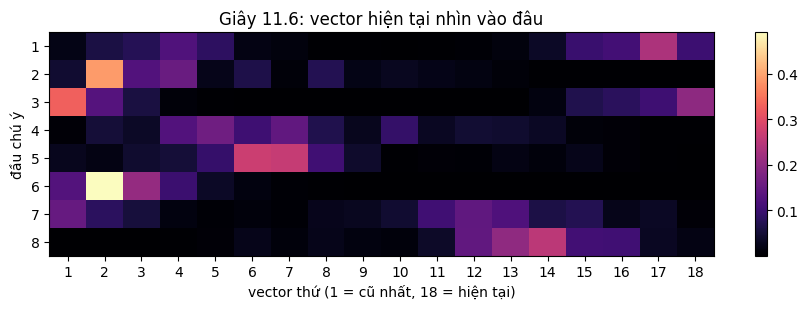

In [13]:
moment = int(baseline_probs[:, FALLEN].argmax())
with torch.no_grad():
    x = classifier.embed(sequences[moment, 0:1].to(DEVICE))
    x = classifier.transformer_encoder.layers[0](x)
    _, weights = classifier.transformer_encoder.layers[1](x, return_weights=True)
print("weights:", tuple(weights.shape), "= (batch, 8 đầu, 18, 18)")

fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(weights[0, :, -1].cpu().numpy(), aspect="auto", cmap="magma")
ax.set_xlabel("vector thứ (1 = cũ nhất, 18 = hiện tại)"); ax.set_ylabel("đầu chú ý")
ax.set_xticks(range(18)); ax.set_xticklabels(range(1, 19)); ax.set_yticks(range(8)); ax.set_yticklabels(range(1, 9))
ax.set_title(f"Giây {seq_times[moment]:.1f}: vector hiện tại nhìn vào đâu")
fig.colorbar(im); plt.tight_layout(); plt.show()

## Bước 9. Quy tắc chuyển trạng thái (0 tham số học)

Công thức: `p̃ₜ = (1 − w)·pₜ + w·eₛ`, với `w(Δt) = 2^(−Δt/τ)`, `0 < Δt ≤ W`, `τ = 1 s`, `W = 5 s`.

Code thật còn 3 chi tiết mà slide lược đi:
- Áp dụng cho **cả 4 cặp** hành động chuyển tiếp → trạng thái tĩnh, không chỉ riêng "đang ngã → đã ngã".
- Thời điểm đang được dự đoán là hành động chuyển tiếp thì không được cộng thêm.
- Điểm được gom thành từng đoạn **0.5 s** rồi mới áp quy tắc (`StreamRule`).

## Bước 10. Báo động

"Đã ngã" giữ liên tục ≥ 1 s thì bật báo động, và phải hết "đã ngã" ≥ 3 s mới tắt, để không bị chớp tắt.

In [14]:
def rule_condition(probs: np.ndarray, starts: np.ndarray, tau: float = TAU, window: float = RULE_WINDOW) -> np.ndarray:
    out, last, pred = probs.copy(), {}, probs.argmax(1)
    for t in range(len(probs)):
        if pred[t] not in TRANSIENT_TO_STATIC:
            for s, t0 in list(last.items()):
                dt = starts[t] - t0
                if dt > window:
                    del last[s]
                    continue
                w = 0.5 ** (dt / tau)
                prior = np.zeros(probs.shape[1]); prior[s] = 1.0     # e_s
                out[t] = (1 - w) * out[t] + w * prior
        else:
            last[TRANSIENT_TO_STATIC[int(pred[t])]] = starts[t]
    return out / out.sum(1, keepdims=True).clip(min=1e-8)


class StreamRule:
    # Nhận xác suất theo dòng thời gian, không được nhìn trước tương lai
    def __init__(self):
        self.step_probs, self.segments, self.last_seg_t = [], [], None
        self.fallen_since = self.clear_since = None
        self.alarm, self.alarm_events = False, []

    def update(self, t: float, p: np.ndarray) -> np.ndarray:
        self.step_probs.append(p)
        if self.last_seg_t is None:
            self.last_seg_t = t
        seg_p = np.mean(self.step_probs, 0)
        if t - self.last_seg_t >= SEGMENT_HOP:
            self.segments = [s for s in self.segments + [(self.last_seg_t, seg_p)] if t - s[0] <= 20.0]
            self.step_probs, self.last_seg_t = [], t
            current = self.segments
        else:
            current = self.segments + [(self.last_seg_t, seg_p)]
        probs = rule_condition(np.stack([x for _, x in current]), np.array([s for s, _ in current]))[-1]
        self._update_alarm(t, int(probs.argmax()))
        return probs

    def _update_alarm(self, t: float, k: int):
        if k == FALLEN:
            self.clear_since = None
            self.fallen_since = t if self.fallen_since is None else self.fallen_since
            if not self.alarm and t - self.fallen_since >= ALARM_ON:
                self.alarm = True
                self.alarm_events.append(t)
        else:
            self.fallen_since = None
            if self.alarm:
                self.clear_since = t if self.clear_since is None else self.clear_since
                if t - self.clear_since >= ALARM_OFF:
                    self.alarm = False


rule = StreamRule()
final_probs = np.stack([rule.update(float(t), p) for t, p in zip(seq_times, baseline_probs)])
print("final_probs:", final_probs.shape)
print("Báo động ở các giây:", [round(t, 2) for t in rule.alarm_events])

final_probs: (59, 10)
Báo động ở các giây: [9.88]


## Toàn bộ luồng trên video thật

Hàng trên là xác suất "đang ngã" và "đã ngã" trước và sau quy tắc. Hàng giữa là nhãn của mô hình. Hàng dưới là nhãn do người gán, nếu video có trong bộ dữ liệu.

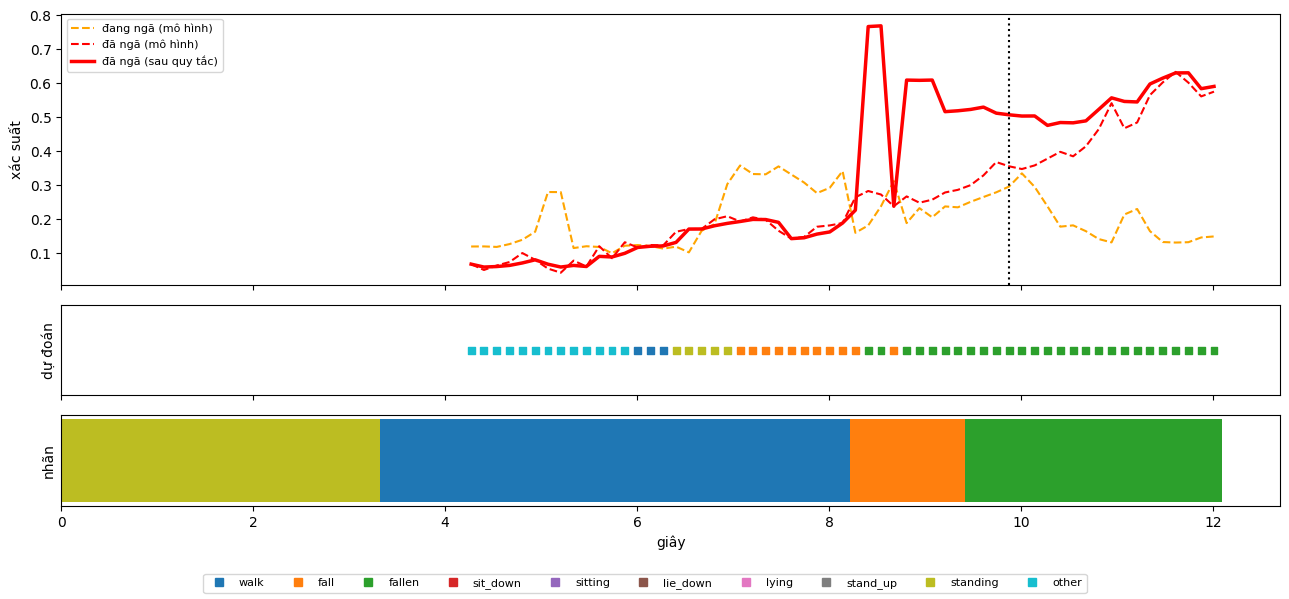

Một vài thời điểm:
 giây  mô hình sau quy tắc
 4.27    other       other
 4.80    other       other
 5.34    other       other
 5.87     walk       other
 6.41 standing    standing
 6.94     fall    standing
 7.47     fall        fall
 8.01     fall        fall
 8.54   fallen      fallen
 9.08     walk      fallen
 9.61   fallen      fallen
10.14   fallen      fallen
10.68   fallen      fallen
11.21   fallen      fallen
11.75   fallen      fallen


In [15]:
base_lab, final_lab = baseline_probs.argmax(1), final_probs.argmax(1)
truth = None
labels_csv = ROOT / "data" / "omnifall" / "labels" / "dataset" / "OOPS.csv"
if labels_csv.exists():
    df = pd.read_csv(labels_csv)
    key = VIDEO.relative_to(ROOT / "data" / "omnifall" / "OOPS" / "video").with_suffix("").as_posix() if ROOT in VIDEO.parents else None
    truth = df[df.path == key].sort_values("start") if key else None

fig, ax = plt.subplots(3, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1]})
ax[0].plot(seq_times, baseline_probs[:, FALL], "--", color="orange", label="đang ngã (mô hình)")
ax[0].plot(seq_times, baseline_probs[:, FALLEN], "--", color="red", label="đã ngã (mô hình)")
ax[0].plot(seq_times, final_probs[:, FALLEN], color="red", lw=2.5, label="đã ngã (sau quy tắc)")
for t in rule.alarm_events:
    ax[0].axvline(t, color="k", ls=":")
ax[0].set_ylabel("xác suất"); ax[0].legend(loc="upper left", fontsize=8)
cmap = plt.get_cmap("tab10")
ax[1].scatter(seq_times, np.zeros_like(seq_times), c=[cmap(k) for k in final_lab], marker="s", s=25); ax[1].set_yticks([]); ax[1].set_ylabel("dự đoán")
if truth is not None and len(truth):
    for _, r in truth.iterrows():
        ax[2].barh(0, r.end - r.start, left=r.start, color=cmap(int(r.label)))
ax[2].set_yticks([]); ax[2].set_ylabel("nhãn"); ax[2].set_xlabel("giây")
handles = [plt.Line2D([], [], marker="s", ls="", color=cmap(i), label=c) for i, c in enumerate(CLASS_NAMES)]
fig.legend(handles=handles, ncol=10, loc="lower center", fontsize=8); plt.tight_layout(rect=(0, .05, 1, 1)); plt.show()

print("Một vài thời điểm:")
print(pd.DataFrame({"giây": seq_times.round(2), "mô hình": [CLASS_NAMES[k] for k in base_lab],
                    "sau quy tắc": [CLASS_NAMES[k] for k in final_lab]}).iloc[:: max(1, len(seq_times) // 12)].to_string(index=False))

## Đo thời gian và đối chiếu với engine của web demo

Ô đầu đo một lần dự đoán thật cho 3 góc, ở float32 và fp16. Kết quả phụ thuộc máy và việc GPU có đang bận hay không. Bản viết tay ở đây tính attention trực tiếp để dễ đọc nên chậm hơn; web demo dùng phép tính attention đã tối ưu của PyTorch, độ trễ của nó được đo ở notebook 08.

Ô thứ hai chạy `FallEngine`, engine mà web demo đang dùng, trên cùng video rồi so với kết quả của notebook. Engine chạy VideoMAE ở dạng fp16 nên có thể lệch rất nhỏ. Ô này cần repo `omnifall-experiments` theo README, nếu thiếu sẽ tự bỏ qua.

In [16]:
import copy


def measure(model, clips, label, repeats=12):
    seq = sequences[0].to(DEVICE)
    ms = []
    with torch.no_grad():
        for i in range(repeats):
            t0 = time.perf_counter()
            model(clips)
            classifier(seq).softmax(-1).mean(0)
            if DEVICE == "cuda":
                torch.cuda.synchronize()
            if i >= 2:
                ms.append((time.perf_counter() - t0) * 1000)
    print(f"{label}: trung bình {np.mean(ms):.1f} ms, trung vị {np.median(ms):.1f} ms")


clips = pixels[:, :WINDOW_FRAMES]
measure(videomae, clips, "float32")
if DEVICE == "cuda":
    fast = copy.deepcopy(videomae).half()       # chế độ fp16 mà web demo dùng
    measure(fast, clips.half(), "fp16")
    del fast
    torch.cuda.empty_cache()
    print(f"GPU đang dùng {torch.cuda.memory_reserved() / 1e9:.1f} GB trong tiến trình này (các chương trình khác cũng làm kết quả chậm đi)")

float32: trung bình 174.0 ms, trung vị 173.7 ms


fp16: trung bình 85.5 ms, trung vị 85.3 ms
GPU đang dùng 1.1 GB trong tiến trình này (các chương trình khác cũng làm kết quả chậm đi)


In [17]:
if (ROOT / "omnifall-experiments" / "models" / "feature_transformer.py").exists():
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    os.environ["TCFALL_BASELINE_CKPT"] = str(FT_CKPT)
    from tcfall.realtime import EngineConfig, FallEngine

    engine = FallEngine(EngineConfig(mode="rule", tau=TAU, window=RULE_WINDOW, segment_hop=SEGMENT_HOP,
                                     alarm_on_seconds=ALARM_ON, alarm_off_seconds=ALARM_OFF, spatial_tta=True))
    records = {}
    for frame, t in zip(frames, times):
        if engine.push_frame(frame, float(t)):
            while engine.pending:
                engine.step()
            if engine.state.ready:
                records[round(float(t), 3)] = (engine.state.baseline_probs.copy(), engine.state.probs.copy())
    common = [i for i, t in enumerate(seq_times) if round(float(t), 3) in records]
    eb = np.stack([records[round(float(seq_times[i]), 3)][0] for i in common])
    ef = np.stack([records[round(float(seq_times[i]), 3)][1] for i in common])
    print(f"So sánh {len(common)}/{len(seq_times)} thời điểm")
    print(f"Xác suất tầng 2 lệch lớn nhất: {np.abs(eb - baseline_probs[common]).max():.4f}")
    print(f"Nhãn cuối trùng khớp: {100 * (ef.argmax(1) == final_lab[common]).mean():.1f}%")
    print("Báo động engine:", [round(x, 2) for x in engine.state.alarm_events], "| notebook:", [round(x, 2) for x in rule.alarm_events])
    del engine
    torch.cuda.empty_cache() if DEVICE == "cuda" else None
else:
    print("Bỏ qua: chưa có omnifall-experiments")

So sánh 59/59 thời điểm
Xác suất tầng 2 lệch lớn nhất: 0.0008
Nhãn cuối trùng khớp: 100.0%
Báo động engine: [9.88] | notebook: [9.88]


## Tra nhanh

| Câu hỏi | Tìm ở đâu |
|---|---|
| 12 lớp Transformer ở đâu? | Bước 3, `VideoMAE.blocks` |
| 12 đầu chú ý? | Bước 3, `VideoMAEAttention`, hàm `split` |
| 1568 khối từ đâu ra? | Bước 2, `TubeletEmbedding`, biến `NUM_PATCHES` |
| Trung bình 1568 → 1? | `VideoMAE.forward`, `.mean(1)` |
| 3 góc gộp ở đâu? | Bước 8, `predict_probs`, `.softmax(-1).mean(1)` |
| 18 vector? | Bước 5, `make_sequences` |
| Mã sin/cos thời gian? | Bước 6, `PositionalEncoding` |
| 2 lớp Encoder, 8 đầu? | Bước 7, `TemporalEncoder.layers`, `TemporalSelfAttention` |
| Softmax 10 lớp? | Bước 8, `predict_probs` |
| τ, W, công thức trộn? | Bước 9, `rule_condition` |
| Điều kiện báo động? | Bước 10, `StreamRule._update_alarm` |
| Số tham số thật? | "Đếm tham số thật" sau Bước 8 và bảng cuối Bước 3 |